# Кейс 6
## Прогнозирование энергопотребления металлургического завода
### Описание кейса: требуется спрогнозировать активную мощность энергопотребления завода по 15-минутным интервалам на основе показателей реактивной мощности, коэффициента нагрузки, выбросов CO2 и календарного графикаа 

Проанализируем описание датасета, приведенного в источнике:

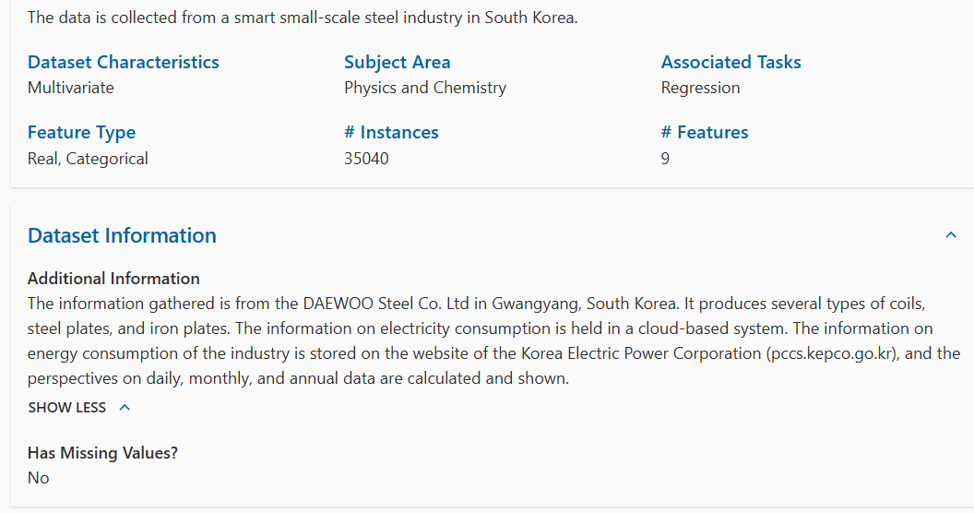

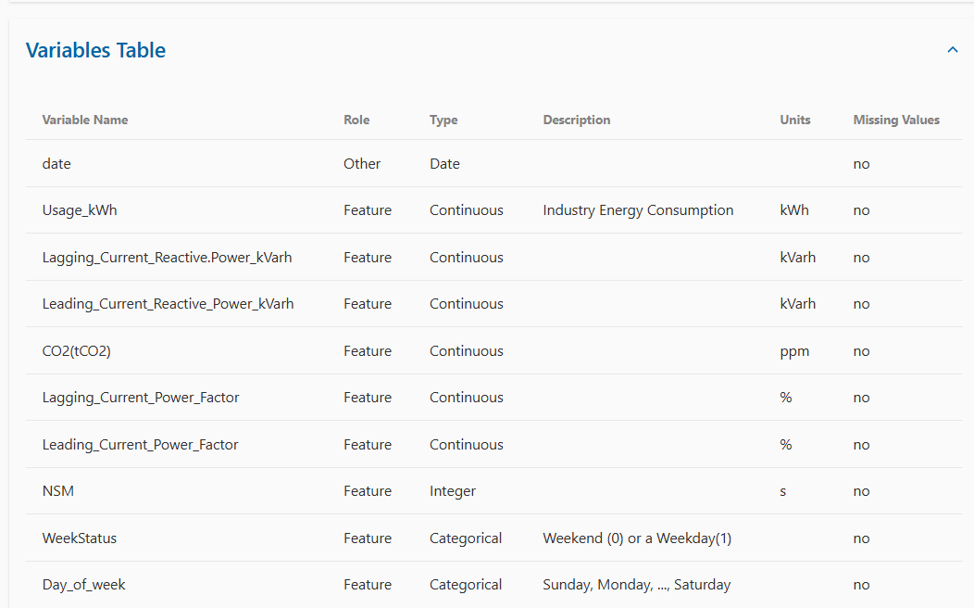

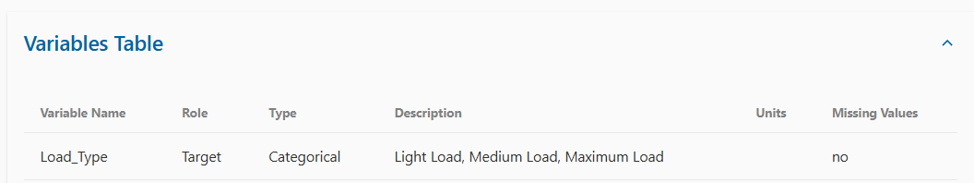

Согласно приведенному описанию, пропусков в данных нет. Это надо проверить!!! В датасете есть непрерывные величины, категориальные, а также даты. В нашем задании целевой переменной (таргетом) является показатель Usage_kWh.

### Что известно про целевую переменную из описания:

Usage_kWh — непрерывная, ≥ 0

Тип задачи: регрессия временного ряда (15-мин интервалы).

### Что важно для модели (надо определить):

- есть ли выраженная суточная/недельная сезонность;

- насколько Usage_kWh объясняется реактивной мощностью и power factor (показывает насколько полно энергия идет на работу, идеальный случай PF = 1, тогда вся энергия идет на совершение работы): Usage_kWh - полезная энергия, реактивная мощность (Lagging, Leading) направлена на создание магнитных полей;

- как ведёт себя CO2 (скорее всего, производная от Usage_kWh);

- как Load_Type соотносится с уровнем мощности.

Давайте внимательно проанализируем сам датасет

In [52]:
# Импорт библиотек и окружения
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import LabelEncoder

# Настройки отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# Воспроизводимость
np.random.seed(42)

# Папка для сохранения графиков для последующего формирования отчета (для удобства)
import os
os.makedirs("eda_plots", exist_ok=True)

def save(fig, name):
    """Сохранить график в папку eda_plots."""
    fig.savefig(f"eda_plots/{name}.png", dpi=100, bbox_inches="tight")

In [54]:
# Загрузка (учитываем BOM в начале файла — используем utf-8-sig и игнорируемы спецсимволы)
df = pd.read_csv("steel+industry+energy+consumption/Steel_industry_data.csv", encoding="utf-8-sig")

Посмотрим первые 5 строк датасета

In [55]:
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


Выполним анализ датасета на пропуски, дубликаты

In [ ]:
print("Размер:", df.shape)
print("\nТипы:\n", df.dtypes)
print("\nПропуски:\n", df.isna().sum())
print("\nДубликаты строк:", df.duplicated().sum())



# Проверим, что даты по возрастанию и без дублей
print("\nДата min/max:", df['date'].min(), df['date'].max()) # покажем самую первую и самую последнюю дату
print("Дубликаты timestamp:", df['date'].duplicated().sum()) # Нет ли дублирующихся записей

# Проверим непрерывность: разница между соседними строками (нет ли у нас пустот и дыр во времени, должны быть отрицательные разницы при перехода на новые сутки 23:45 - 0:00)
diffs = df['date'].diff().dropna().value_counts()
print("\nЧастоты интервалов между строками:\n", diffs.head())

# Базовые категории
for col in ['WeekStatus', 'Day_of_week', 'Load_Type']:
    print(f"\n{col}:\n", df[col].value_counts())

Размер: (35040, 11)

Типы:
 date                                     object
Usage_kWh                               float64
Lagging_Current_Reactive.Power_kVarh    float64
Leading_Current_Reactive_Power_kVarh    float64
CO2(tCO2)                               float64
Lagging_Current_Power_Factor            float64
Leading_Current_Power_Factor            float64
NSM                                       int64
WeekStatus                               object
Day_of_week                              object
Load_Type                                object
dtype: object

Пропуски:
 date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             

Давайте подведем итоги:
1) Размер (35040, 11): У нас 35 040 строк и 11 столбцов. 35 040 — это 365 дней в году, умноженные на 96 (в сутках 24 часа × 4 пятнадцатиминутных интервала = 96). Значит, у нас ровно один год данных с шагом в 15 минут.
2) Типы: Столбец date имеет тип object (это просто текст). Остальные — числа (float64, int64) и категории (object для дней недели и типа нагрузки). Параметр date надо привести к формату datetime.

In [60]:
# Приводим даты к формату DD/MM/YYYY HH:MM
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y %H:%M')
print(df['date'].dtype)

datetime64[ns]


3. Пропуски и дубликаты
	- Пропуски: 0 везде.
    - Дубликаты строк: 0. Нет повторяющихся записей.
    - Дубликаты timestamp: 0. На каждую 15-минутную отметку времени есть ровно одна запись. Временной ряд непрерывный, без задвоений.


4. Даты и интервалы
    - Дата min/max: Данные ровно за 2018 год — с 1 января по 31 декабря. Можно проанализировать сезонность (зима, весна, лето, осень).
    - Частоты интервалов:
    - 0 days 00:15:00 — 34 310 раз. Нрмальный шаг в 15 минут между строками.
    - -1 days +00:15:00 — 365 раз, переход через полночь (с 23:45 на 00:00). Разница отрицательная (-23 часа 45 минут), но легко объясняется: это просто переход на следующие сутки.
    - 1 days 00:15:00 — 364 раза. "Обратный" переход (в файле есть моменты, когда время 00:00 идет после 23:45).

Вывод: Пропущенных интервалов нет. Временной ряд непрерывный.


5. Категориальные признаки
    - WeekStatus (Статус недели): 25 056 будних дней и 9 984 выходных. В году примерно 261 будний день и 104 выходных. Если умножить на 96 интервалов в сутках — получаются указанные значения.
    - Day_of_week (День недели): Понедельников больше (5088), чем остальных дней (по 4992). Согласно календарным данным, 2018 год начался с понедельника, и таких дней в году оказалось 53.
    - Load_Type (Тип нагрузки): Больше всего Light_Load (около половины), затем Medium_Load и Maximum_Load. Это классы нагрузки, которые могут помочь при создании модели.


### Общие выводы первичного анализа
 1. Данные чистые. Отсутствуют пропуски или битые даты.
 2.	Идеальный временной ряд. Данные за целый год без единого пропуска.
 3.	Можно строить базовую статистику.


## Построение базовой статистики

In [58]:
print(df.describe().T)

# Отдельно посмотрим на min/max по ключевым столбцам
print("--- ОБЩАЯ СТАТИСТИКА ---")
print(df.describe().T)

num_cols = ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh',
            'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)',
            'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM']

# Выводим конкретные метрики по колонкам
print("\n--- КЛЮЧЕВЫЕ МЕТРИКИ ---")
print(df[num_cols].agg(['min', 'max', 'mean', 'median', 'std']).T)

                                        count                 mean                  min                  25%                  50%                  75%                  max           std
date                                    35040  2018-07-02 11:52:30  2018-01-01 00:00:00  2018-04-02 05:56:15  2018-07-02 11:52:30  2018-10-01 17:48:45  2018-12-31 23:45:00           NaN
Usage_kWh                             35040.0            27.386892                  0.0                  3.2                 4.57              51.2375               157.18      33.44438
Lagging_Current_Reactive.Power_kVarh  35040.0            13.035384                  0.0                  2.3                  5.0                22.64                96.91        16.306
Leading_Current_Reactive_Power_kVarh  35040.0             3.870949                  0.0                  0.0                  0.0                 2.09                27.76      7.424463
CO2(tCO2)                             35040.0             0.011524    

### Выводы:
1. Usage_kWh (таргет — активная мощность)
    - min = 0.0: В некоторые моменты завод вообще не потреблял энергию.
    - max = 157.18: Самый высокий пик потребления за год.
    - mean (среднее) = 27.38, а median (медиана) = 4.57.
Что это значит: Медиана в 6 раз меньше среднего! Имеется сильный перекос (асимметрия). Половину времени завод работает на очень низкой мощности (около 4 кВт·ч), но иногда случаются огромные пики (до 150+).





2. Реактивная мощность (Lagging и Leading)
    - Lagging (Запаздывающая): Максимум 96.91, среднее 13.0. Она почти всегда больше нуля и растет вместе с потреблением. Хорошая фича.
    - Leading (Опережающая): Минимум 0, максимум 27.76, медиана 0. Это значит, что в большинстве случаев она равна нулю (нет компенсации), но иногда включается.
Вывод: Lagging и Leading работают в разных режимах. Модели нужно будет понимать время суток, чтобы понимать, какой режим сейчас активен.

Краткое пояснение запаздывания и опережения:
- Lagging (Запаздывание): Случай, когда работает обычный электродвигатель, ток «отстает» от напряжения. Это стандартное состояние большинства заводов. Двигатели потребляют реактивную мощность, чтобы создать магнитное поле.
- Leading (Опережение): Ток «убегает» вперед напряжения. Это происходит, когда в сети находятся конденсаторы. Они не потребляют реактивную мощность, а генерируют её.


3. CO2 (Выбросы)
- min = 0.0
- max = 0.07 (всего 7 сотых!)
- median = 0.0
- mean = 0.011

Что это значит: Больше половины времени выбросы CO2 равны нулю. Но при этом Usage_kWh в эти же моменты может быть 50, 100 или 150. Это физически невозможно — если завод потребляет энергию, он не может выделять 0 CO2.
Скорее всего, датчик CO2 на заводе работал криво или данные не были записаны.
CO2 - кандидат на исключение из параметров. Модель на него не должна опираться.


4. Power Factor (Коэффициент мощности)
- Lagging PF: min 0, max 100, median 87.96.
- Leading PF: min 0, max 100, median 100.
- Зачем он нужен: Если коэффициент мощности низкий (например, 50), значит, завод потребляет много реактивной энергии и мало полезной. Это важный технический показатель для модели.


## Анализ целевой переменной Usage_kWh

Построим три диаграммы:
1.	Обычная гистограмма (чтобы увидеть, перекос).
2.	Логарифмическая (чтобы проверить, насколько выровняется признак).
3.	"Ящик с усами" (Boxplot) по типам нагрузки (Load_Type).


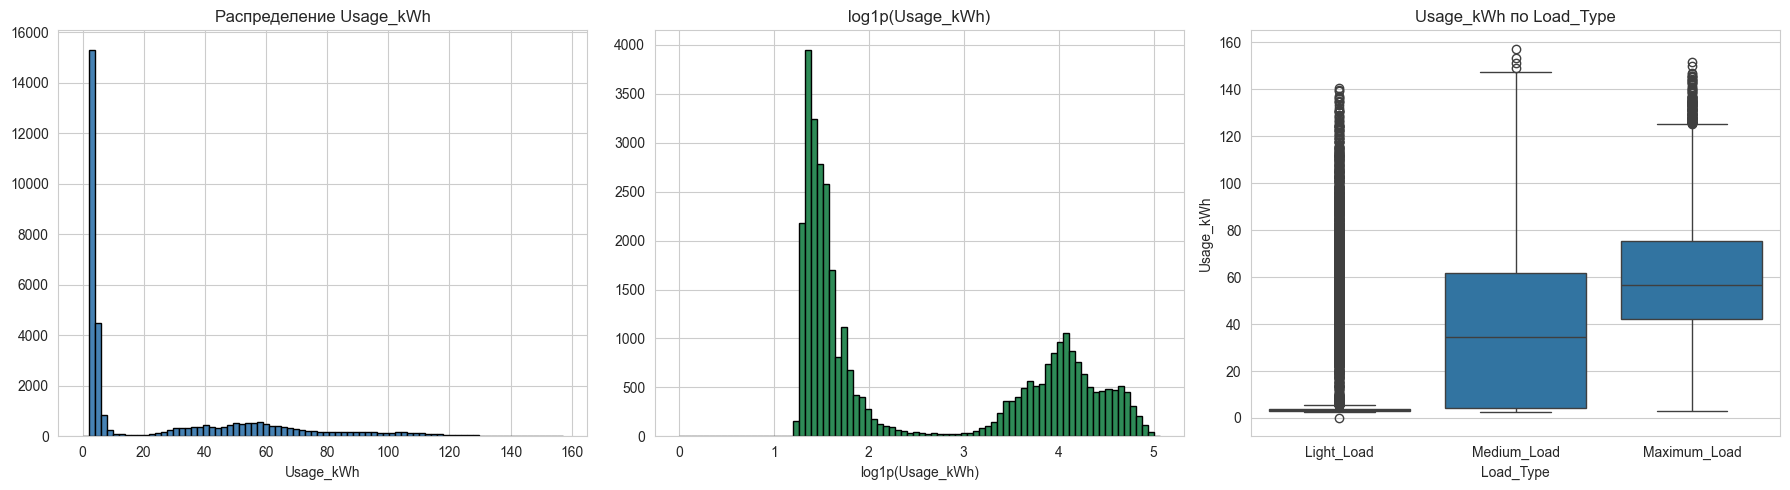

Skew: 1.1973938227692205
Kurtosis: 0.391385601423929
Доля > 100 кВт·ч: 0.04800228310502283


In [61]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Гистограмма
axes[0].hist(df['Usage_kWh'], bins=80, color='steelblue', edgecolor='black')
axes[0].set_title("Распределение Usage_kWh")
axes[0].set_xlabel("Usage_kWh")

# 2) Лог-гистограмма
axes[1].hist(np.log1p(df['Usage_kWh']), bins=80, color='seagreen', edgecolor='black')
axes[1].set_title("log1p(Usage_kWh)")
axes[1].set_xlabel("log1p(Usage_kWh)")

# 3) Boxplot по Load_Type
sns.boxplot(data=df, x='Load_Type', y='Usage_kWh', ax=axes[2])
axes[2].set_title("Usage_kWh по Load_Type")

plt.tight_layout()
save(fig, "01_target_distribution")
plt.show()

# Скошенность и эксцесс
print("Skew:", df['Usage_kWh'].skew())
print("Kurtosis:", df['Usage_kWh'].kurt())
print("Доля > 100 кВт·ч:", (df['Usage_kWh'] > 100).mean())

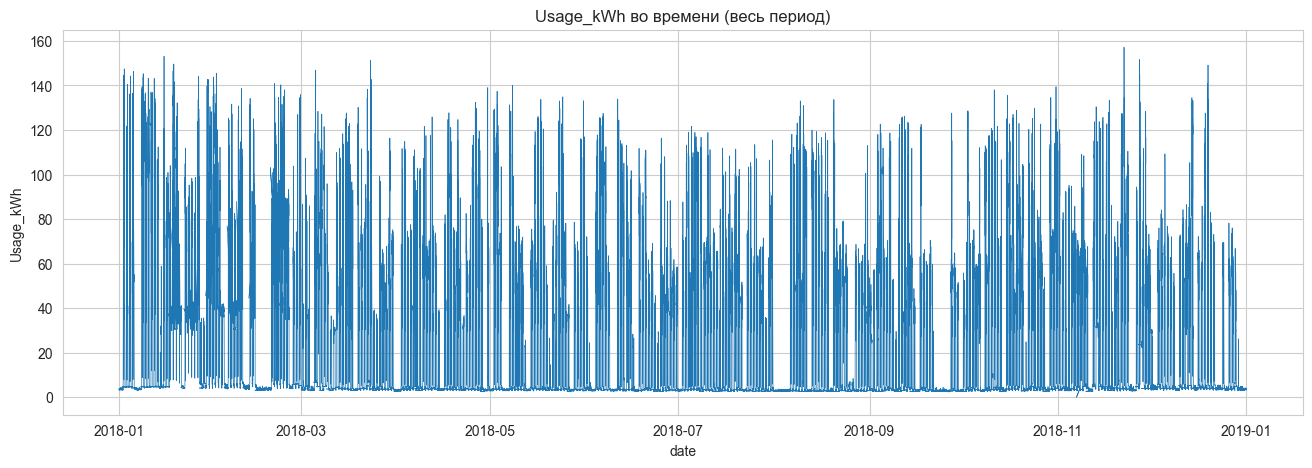

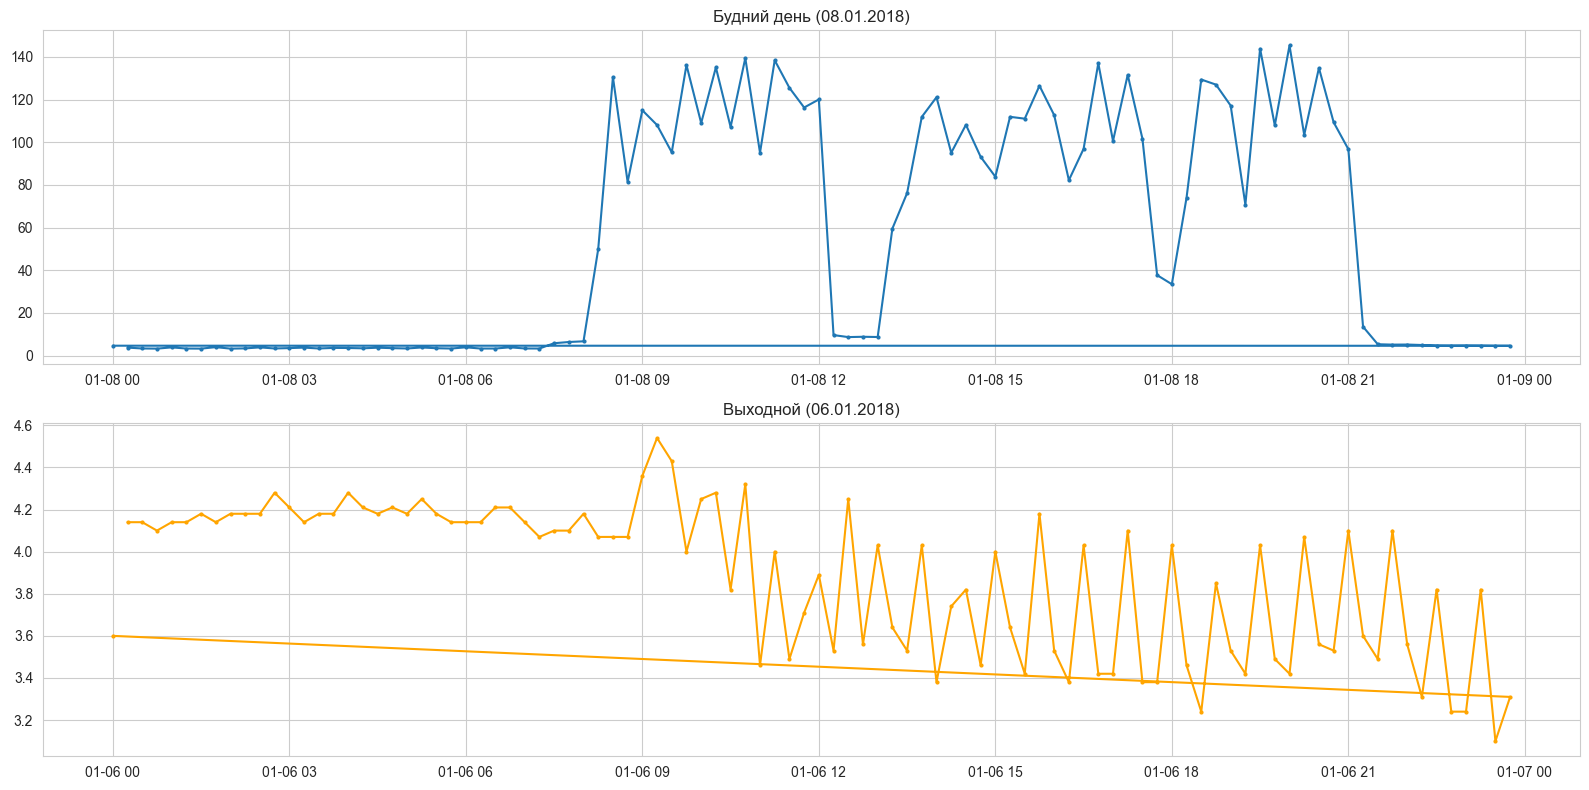

In [35]:
# Полный ряд
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df['date'], df['Usage_kWh'], linewidth=0.5)
ax.set_title("Usage_kWh во времени (весь период)")
ax.set_xlabel("date")
ax.set_ylabel("Usage_kWh")
save(fig, "02_full_timeseries")
plt.show()

# Один типичный будний день и один выходной для наглядности
sample_weekday = df[(df['date'] >= '2018-01-08') & (df['date'] < '2018-01-09')]
sample_weekend = df[(df['date'] >= '2018-01-06') & (df['date'] < '2018-01-07')]

fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=False)
axes[0].plot(sample_weekday['date'], sample_weekday['Usage_kWh'], marker='o', ms=2)
axes[0].set_title("Будний день (08.01.2018)")
axes[1].plot(sample_weekend['date'], sample_weekend['Usage_kWh'], marker='o', ms=2, color='orange')
axes[1].set_title("Выходной (06.01.2018)")
plt.tight_layout()
save(fig, "03_weekday_vs_weekend")
plt.show()